# 데이터 탐색 (EDA)

가상 게임 3개(냥기사의 여행 NAI, 0x72 DungeonTileset II, KayKit Adventurers)와 굿즈 사진 데이터의 수량·해상도·생성 정보·색 분포를 확인하고, 전처리 기준을 정한다.

## 설정

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

RAW = Path('../data/raw')
NAI_DIR = RAW / 'nai'
PIX_DIR = RAW / 'pixel_0x72'
KAY_DIR = RAW / 'kaykit'
GOODS_DIR = RAW / 'goods'
FIG_DIR = Path('../outputs/data_eda')
FIG_DIR.mkdir(parents=True, exist_ok=True)

# 한글 제목이 깨지지 않도록 Windows 기본 한글 폰트 지정
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

## 1. 냥기사의 여행 (NAI)

### 1-1. 생성 정보와 분류

NAI PNG의 `Comment` 메타데이터에서 시드·스텝 등을 읽고, 프롬프트 키워드로 이미지 종류를 분류한다.

NAI 이미지 수: 17 | 생성 정보 있음: 17
해상도: {(1024, 1024): 17}


,file,width,height,mode,has_meta,seed,steps,scale,sampler,category
0,"game screenshot, side view, 2d side-scrolling ...",1024,1024,RGBA,True,106634957,23,5.0,k_euler_ancestral,game screenshot
1,"game screenshot, side view, 2d side-scrolling ...",1024,1024,RGBA,True,2737766560,23,5.0,k_euler_ancestral,game screenshot
2,"no humans, animal focus, a small black cat adv...",1024,1024,RGBA,True,3635442602,23,7.0,k_euler_ancestral,character sheet
3,"no humans, animal focus, a small black cat adv...",1024,1024,RGBA,True,4048534430,23,7.0,k_euler_ancestral,character sheet
4,"no humans, animal focus, black cat, large yell...",1024,1024,RGBA,True,3266381102,23,7.0,k_euler_ancestral,main character scene
5,"no humans, black cat adventurer standing uprig...",1024,1024,RGBA,True,1864801818,23,5.0,k_euler_ancestral,main character scene
6,"no humans, black cat adventurer standing uprig...",1024,1024,RGBA,True,3013732252,23,5.0,k_euler_ancestral,main character scene
7,"no humans, black cat adventurer standing uprig...",1024,1024,RGBA,True,674671886,23,5.0,k_euler_ancestral,main character scene
8,"no humans, black cat adventurer, yellow eyes, ...",1024,1024,RGBA,True,1188371166,23,5.0,k_euler_ancestral,main character scene
9,"no humans, black cat adventurer, yellow eyes, ...",1024,1024,RGBA,True,4034516591,23,5.0,k_euler_ancestral,main character scene


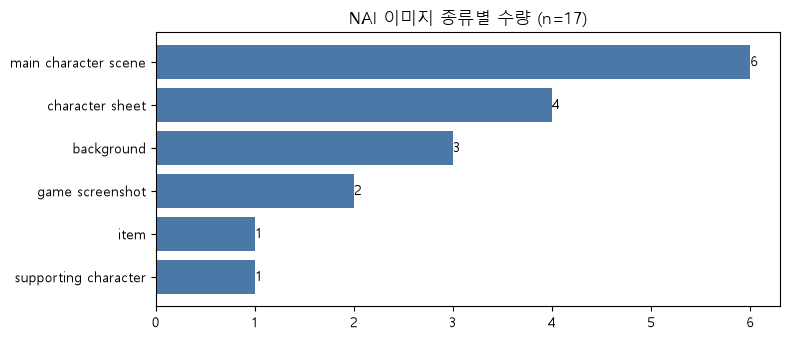

In [2]:
def nai_category(prompt):
    p = prompt.lower()
    if 'turnaround' in p or 'reference sheet' in p:
        return 'character sheet'
    if 'game screenshot' in p:
        return 'game screenshot'
    if 'item icon' in p:
        return 'item'
    if 'no animals' in p and 'scenery' in p:
        return 'background'
    if any(k in p for k in ['rabbit', 'owl', 'dog', 'slime']):
        return 'supporting character'
    return 'main character scene'

rows = []
for p in sorted(NAI_DIR.glob('*.png')):
    im = Image.open(p)
    meta = json.loads(im.info['Comment']) if 'Comment' in im.info else {}
    prompt = meta.get('prompt', '')
    rows.append({
        'file': p.name, 'width': im.width, 'height': im.height, 'mode': im.mode,
        'has_meta': bool(meta), 'seed': meta.get('seed'), 'steps': meta.get('steps'),
        'scale': meta.get('scale'), 'sampler': meta.get('sampler'),
        'category': nai_category(prompt), 'prompt': prompt,
    })
nai = pd.DataFrame(rows)
print('NAI 이미지 수:', len(nai), '| 생성 정보 있음:', nai.has_meta.sum())
print('해상도:', nai.groupby(['width', 'height']).size().to_dict())
display(nai.drop(columns='prompt'))

counts = nai.category.value_counts()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(counts.index, counts.values, color='#4C78A8')
ax.bar_label(ax.containers[0])
ax.set_title(f'NAI 이미지 종류별 수량 (n={len(nai)})')
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(FIG_DIR / 'nai_category_counts.png', dpi=100)
plt.show()

### 1-2. 전체 이미지 확인

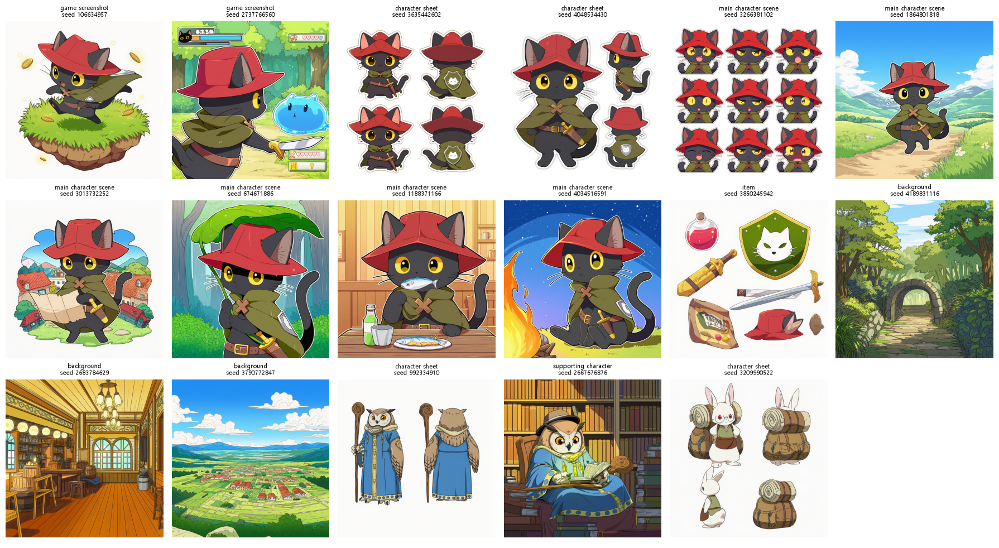

In [3]:
n = len(nai)
cols = 6
rows_n = (n + cols - 1) // cols
fig, axes = plt.subplots(rows_n, cols, figsize=(3 * cols, 3.3 * rows_n), squeeze=False)
for ax in axes.flat:
    ax.axis('off')
for ax, r in zip(axes.flat, nai.itertuples()):
    ax.imshow(Image.open(NAI_DIR / r.file).convert('RGB'))
    ax.set_title(f'{r.category}\nseed {r.seed}', fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / 'nai_contact_sheet.png', dpi=80)
plt.show()

### 1-3. 색 분포

같은 그림체라면 밝기·채도 분포가 모여 있어야 한다. 흩어진 이미지는 학습·레퍼런스 데이터에서 제외 후보로 본다.

> 6-4 검증 결과, 이 기준은 그림체가 아니라 장면 밝기를 거른다. 같은 모델·설정으로 만든 NAI 800장 중 52장이 제외 후보가 되고(제외 후보의 69.2%가 밤 장면, 나머지는 19.3%), 그림체가 다른 KayKit은 26.7%가 범위 안에 든다.

saturation        brightness       
                           mean    std       mean    std
category                                                
background                0.523  0.151      0.645  0.139
character sheet           0.145  0.030      0.810  0.067
game screenshot           0.339  0.135      0.743  0.097
item                      0.202    NaN      0.873    NaN
main character scene      0.397  0.127      0.715  0.085
supporting character      0.445    NaN      0.472    NaN

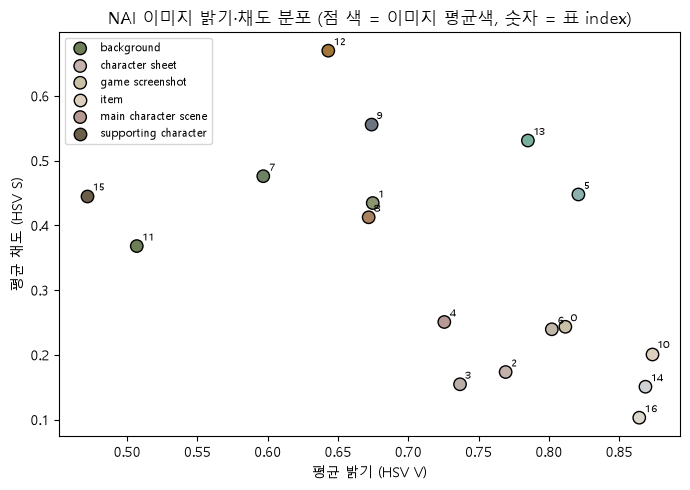

In [4]:
def color_stats(path):
    rgb = np.asarray(Image.open(path).convert('RGB').resize((256, 256)), dtype=np.float32) / 255
    hsv = np.asarray(Image.open(path).convert('RGB').resize((256, 256)).convert('HSV'), dtype=np.float32) / 255
    return rgb.mean(axis=(0, 1)), hsv[..., 1].mean(), hsv[..., 2].mean()

stats = [color_stats(NAI_DIR / f) for f in nai.file]
nai['mean_rgb'] = [s[0] for s in stats]
nai['saturation'] = [s[1] for s in stats]
nai['brightness'] = [s[2] for s in stats]
display(nai.groupby('category')[['saturation', 'brightness']].agg(['mean', 'std']).round(3))

fig, ax = plt.subplots(figsize=(7, 5))
for cat, g in nai.groupby('category'):
    ax.scatter(g.brightness, g.saturation, s=80, label=cat, c=np.stack(g.mean_rgb), edgecolors='black')
for r in nai.itertuples():
    ax.annotate(str(r.Index), (r.brightness, r.saturation), fontsize=7, xytext=(4, 4), textcoords='offset points')
ax.set_xlabel('평균 밝기 (HSV V)')
ax.set_ylabel('평균 채도 (HSV S)')
ax.set_title('NAI 이미지 밝기·채도 분포 (점 색 = 이미지 평균색, 숫자 = 표 index)')
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / 'nai_color_scatter.png', dpi=100)
plt.show()

## 2. 0x72 DungeonTileset II (픽셀)

### 2-1. 파일 구성

`frames` 폴더의 파일명(`이름_동작_anim_f번호`)으로 캐릭터·동작·프레임을 나눈다.

PNG 수: 376 | 애니메이션 프레임: 210 | 캐릭터·몬스터 종류: 25
아틀라스(여러 타일을 모은 큰 이미지): ['0x72_DungeonTilesetII_v1.7.png', 'atlas_floor-16x16.png', 'atlas_walls_high-16x32.png', 'atlas_walls_low-16x16.png', 'doc.png', 'pumpkin_dude.png']


width  height
16     16        150
       28         90
       23         64
32     36         24
6      7           4
10     21          3
13     12          3
14     26          2
16     24          2
       32          2
Name: count, dtype: int64

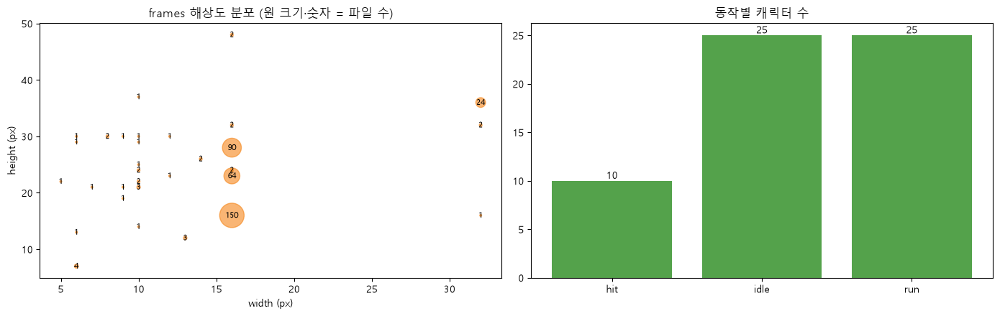

In [5]:
# scenes는 10/16에 만든 학습 데이터(6번 섹션) → 2번은 원본 팩 구성만 본다
pix_files = sorted(p for p in PIX_DIR.rglob('*.png') if 'scenes' not in p.parts)
pat = re.compile(r'^(?P<entity>.+?)_(?P<action>idle|run|hit)_anim_f(?P<frame>\d+)$')
prow = []
for p in pix_files:
    im = Image.open(p)
    m = pat.match(p.stem)
    prow.append({
        'file': p.name, 'folder': p.parent.name, 'width': im.width, 'height': im.height,
        'mode': im.mode, 'entity': m['entity'] if m else None,
        'action': m['action'] if m else None, 'frame': int(m['frame']) if m else None,
    })
pix = pd.DataFrame(prow)
anim = pix.dropna(subset=['entity'])
print('PNG 수:', len(pix), '| 애니메이션 프레임:', len(anim), '| 캐릭터·몬스터 종류:', anim.entity.nunique())
print('아틀라스(여러 타일을 모은 큰 이미지):', pix[pix.folder != 'frames'].file.tolist())
display(pix.groupby(['width', 'height']).size().sort_values(ascending=False).head(10).rename('count'))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 4.5))
size_counts = pix[pix.folder == 'frames'].groupby(['width', 'height']).size()
a1.scatter([w for w, h in size_counts.index], [h for w, h in size_counts.index], s=size_counts.values * 4, alpha=0.6, color='#F58518')
for (w, h), c in size_counts.items():
    a1.annotate(str(c), (w, h), fontsize=8, ha='center', va='center')
a1.set_xlabel('width (px)')
a1.set_ylabel('height (px)')
a1.set_title('frames 해상도 분포 (원 크기·숫자 = 파일 수)')
act = anim.groupby('action').entity.nunique()
a2.bar(act.index, act.values, color='#54A24B')
a2.bar_label(a2.containers[0])
a2.set_title('동작별 캐릭터 수')
plt.tight_layout()
plt.savefig(FIG_DIR / 'pixel_sizes_actions.png', dpi=100)
plt.show()

### 2-2. 캐릭터 샘플

원본이 16px 단위라 확대 시 픽셀 경계가 유지되도록 nearest 보간으로 8배 키워 확인한다.

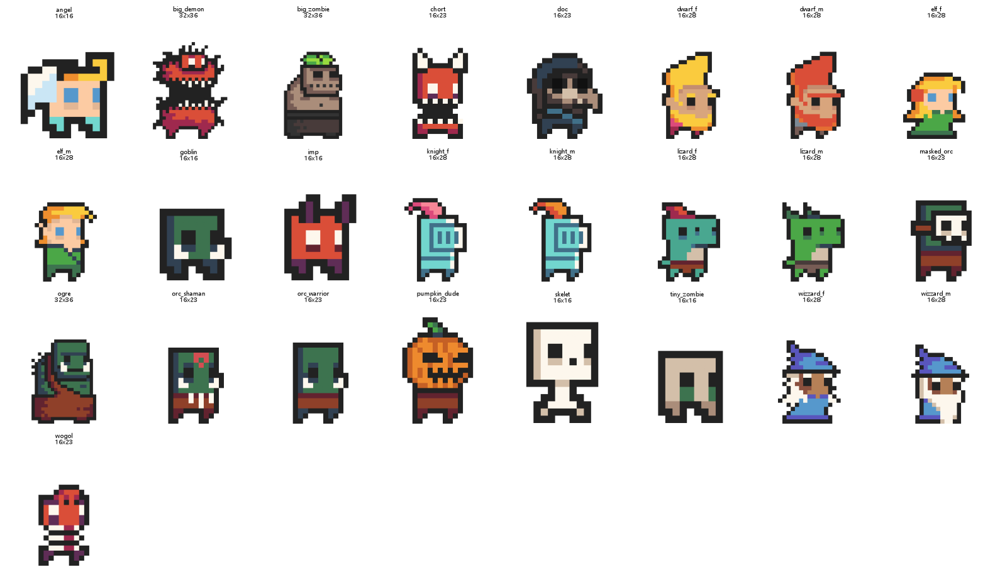

In [6]:
idle0 = anim[(anim.action == 'idle') & (anim.frame == 0)].sort_values('entity')
n = len(idle0)
cols = 8
rows_n = (n + cols - 1) // cols
fig, axes = plt.subplots(rows_n, cols, figsize=(2 * cols, 2.3 * rows_n), squeeze=False)
for ax in axes.flat:
    ax.axis('off')
frames_dir = next(PIX_DIR.rglob('frames'))
for ax, r in zip(axes.flat, idle0.itertuples()):
    im = Image.open(frames_dir / r.file).convert('RGBA')
    ax.imshow(im.resize((im.width * 8, im.height * 8), Image.NEAREST))
    ax.set_title(f'{r.entity}\n{r.width}x{r.height}', fontsize=7)
plt.tight_layout()
plt.savefig(FIG_DIR / 'pixel_idle_sprites.png', dpi=90)
plt.show()

### 2-3. 색 수와 투명 영역

픽셀아트는 이미지당 사용 색 수가 적다. 생성 결과를 픽셀아트로 후처리할 때 색 수 축소 기준으로 쓴다.

       n_colors  opaque_ratio
count   210.000       210.000
mean      6.429         0.423
std       1.592         0.059
min       3.000         0.281
25%       5.000         0.386
50%       7.000         0.431
75%       7.000         0.459
max       9.000         0.582


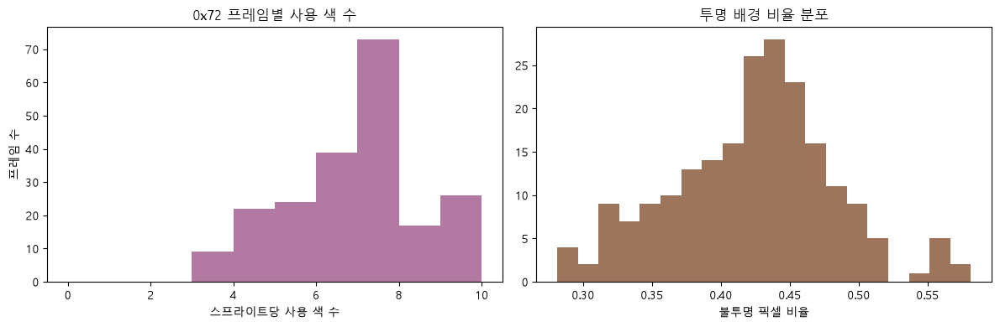

In [7]:
def pixel_stats(path):
    a = np.asarray(Image.open(path).convert('RGBA'))
    opaque = a[..., 3] > 0
    colors = np.unique(a[opaque][:, :3], axis=0) if opaque.any() else np.empty((0, 3))
    return len(colors), opaque.mean()

ps = [pixel_stats(frames_dir / f) for f in anim.file]
anim = anim.assign(n_colors=[s[0] for s in ps], opaque_ratio=[s[1] for s in ps])
print(anim[['n_colors', 'opaque_ratio']].describe().round(3))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.hist(anim.n_colors, bins=range(0, anim.n_colors.max() + 2), color='#B279A2')
a1.set_xlabel('스프라이트당 사용 색 수')
a1.set_ylabel('프레임 수')
a1.set_title('0x72 프레임별 사용 색 수')
a2.hist(anim.opaque_ratio, bins=20, color='#9D755D')
a2.set_xlabel('불투명 픽셀 비율')
a2.set_title('투명 배경 비율 분포')
plt.tight_layout()
plt.savefig(FIG_DIR / 'pixel_colors_alpha.png', dpi=100)
plt.show()

## 3. KayKit Adventurers (3D 로우폴리)

3D 모델 팩이라 바로 쓸 이미지는 `Samples` 폴더의 미리보기 렌더뿐이다.

.fbx     32
.png     28
.bin     27
.gltf    27
.glb      5
.txt      2
.url      2
.md       1
Name: count, dtype: int64

미리보기 렌더: 6 | 텍스처: 4


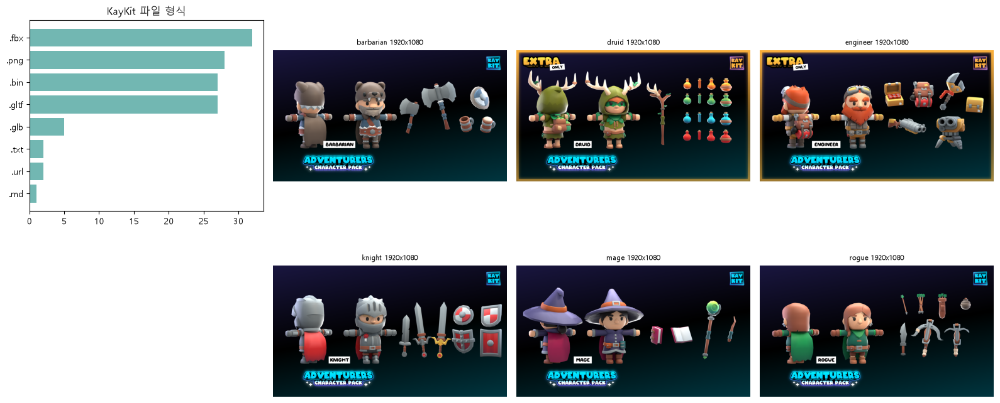

In [8]:
# renders는 10/16에 만든 학습 데이터(6번 섹션) → 3번은 원본 팩 구성만 본다
kfiles = [p for p in KAY_DIR.rglob('*') if p.is_file() and 'renders' not in p.parts]
ext = pd.Series([p.suffix.lower() or p.name for p in kfiles]).value_counts()
display(ext.rename('count'))

samples = sorted(KAY_DIR.rglob('Samples/*.png'))
textures = sorted(KAY_DIR.rglob('Textures/*.png'))
print('미리보기 렌더:', len(samples), '| 텍스처:', len(textures))

fig = plt.figure(figsize=(16, 7))
ax0 = fig.add_subplot(2, 4, 1)
ax0.barh(ext.index, ext.values, color='#72B7B2')
ax0.set_title('KayKit 파일 형식')
ax0.invert_yaxis()
for i, p in enumerate(samples[:6]):
    ax = fig.add_subplot(2, 4, i + 2 if i < 3 else i + 3)
    im = Image.open(p)
    ax.imshow(im)
    ax.set_title(f'{p.stem} {im.width}x{im.height}', fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR / 'kaykit_overview.png', dpi=90)
plt.show()

## 4. 굿즈 사진

### 4-1. 무료 사진 사이트에서 무지 굿즈 사진 받기 (10/20 결정)

10/20에 굿즈 사진을 직접 촬영하지 않고 Unsplash·Pexels 무료 사진 11장(티셔츠 2, 머그 4, 토트백 3, 후드 2)으로 쓰기로 했다. 아래 셀이 사진을 `data/raw/goods`에 받고, 출처·라이선스를 `goods_sources.csv`에 함께 저장한다.

- 라이선스
  - Unsplash License: "download, copy, modify, distribute, perform, and use images from Unsplash for free, including for commercial purposes, without permission from or attributing the photographer". Unsplash+(유료) 사진은 넣지 않았다.
  - Pexels License: "Use all photos for free for commercial and noncommercial purposes", "You can edit and adapt the photos as you like"
- 고른 기준: 무료 라이선스이고, 사진 설명이 무늬·글자가 없는 무지 굿즈이며, 굿즈가 사진의 주인공인 것. 사진 설명으로만 골랐으므로, 받은 뒤 그림으로 무늬·로고가 없는지 확인한다.
- 이미 받은 파일은 건너뛴다.

mug_01.jpg 3122 3609 
mug_02.jpg 3000 2000 
mug_03.jpg 5023 3349 
mug_04.jpg 5367 3578 
tshirt_01.jpg 3000 2000 
tshirt_02.jpg 3000 2000 
tote_01.jpg 5472 3648 
tote_02.jpg 3712 5568 
tote_03.jpg 2532 4500 
hoodie_01.jpg 5536 4160 
hoodie_02.jpg 2160 3840 


,file,kind,site,license,page,error,width,height,mode,mb
0,mug_01.jpg,mug,unsplash,Unsplash License (https://unsplash.com/license),https://unsplash.com/photos/white-ceramic-mug-...,,3122,3609,RGB,0.47
1,mug_02.jpg,mug,unsplash,Unsplash License (https://unsplash.com/license),https://unsplash.com/photos/a-white-coffee-mug...,,3000,2000,RGB,0.36
2,mug_03.jpg,mug,unsplash,Unsplash License (https://unsplash.com/license),https://unsplash.com/photos/white-ceramic-mug-...,,5023,3349,RGB,1.02
3,mug_04.jpg,mug,pexels,Pexels License (https://www.pexels.com/license/),https://www.pexels.com/photo/plain-white-mugs-...,,5367,3578,RGB,1.43
4,tshirt_01.jpg,tshirt,unsplash,Unsplash License (https://unsplash.com/license),https://unsplash.com/photos/a-white-shirt-on-a...,,3000,2000,RGB,0.17
5,tshirt_02.jpg,tshirt,unsplash,Unsplash License (https://unsplash.com/license),https://unsplash.com/photos/a-plain-white-t-sh...,,3000,2000,RGB,0.43
6,tote_01.jpg,tote,unsplash,Unsplash License (https://unsplash.com/license),https://unsplash.com/photos/white-reusable-bag...,,5472,3648,RGB,3.60
7,tote_02.jpg,tote,unsplash,Unsplash License (https://unsplash.com/license),https://unsplash.com/photos/beige-eco-bag-1Pgq...,,3712,5568,RGB,2.89
8,tote_03.jpg,tote,unsplash,Unsplash License (https://unsplash.com/license),https://unsplash.com/photos/a-white-bag-hangin...,,2532,4500,RGB,1.11
9,hoodie_01.jpg,hoodie,unsplash,Unsplash License (https://unsplash.com/license),https://unsplash.com/photos/white-hoodie-and-d...,,5536,4160,RGB,2.57


받음 11 / 11


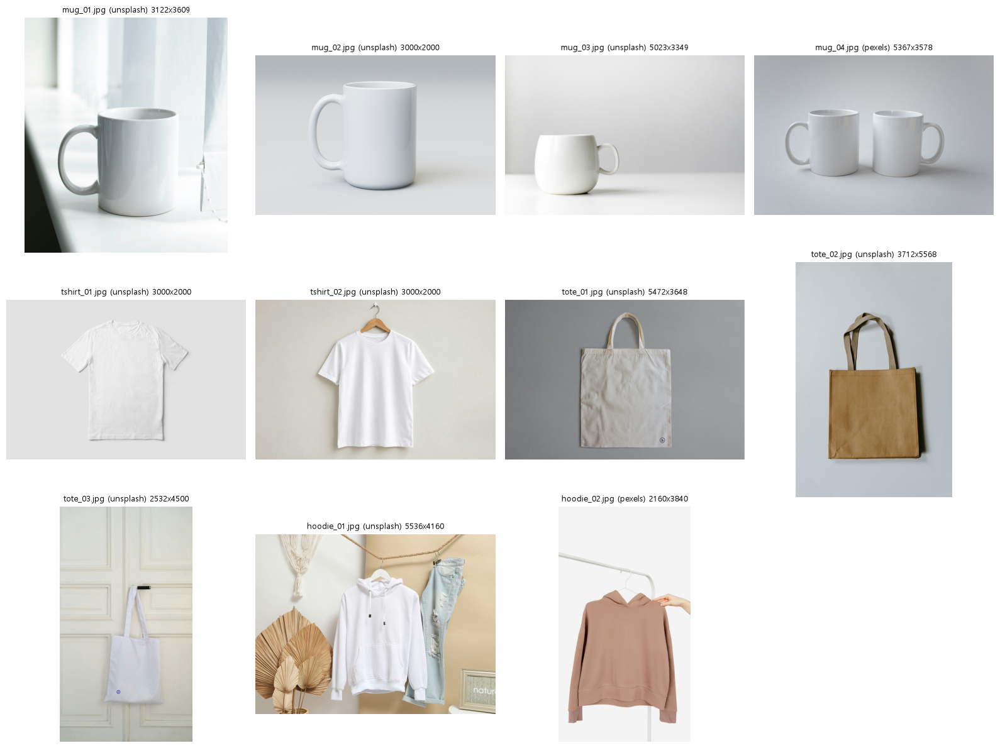

In [10]:
import html
import re
import urllib.request

GOODS_DIR.mkdir(parents=True, exist_ok=True)
# (파일 이름, 품목, 사이트, 사진 페이지)
GOODS = [
    ('mug_01.jpg', 'mug', 'unsplash', 'https://unsplash.com/photos/white-ceramic-mug-on-white-table-he_xuL-CyyI'),
    ('mug_02.jpg', 'mug', 'unsplash', 'https://unsplash.com/photos/a-white-coffee-mug-xf38DdLyBvI'),
    ('mug_03.jpg', 'mug', 'unsplash', 'https://unsplash.com/photos/white-ceramic-mug-nDd3dIkkOLo'),
    ('mug_04.jpg', 'mug', 'pexels', 'https://www.pexels.com/photo/plain-white-mugs-on-a-white-surface-6312177/'),
    ('tshirt_01.jpg', 'tshirt', 'unsplash', 'https://unsplash.com/photos/a-white-shirt-on-a-white-background-4rUYuwJ2vGw'),
    ('tshirt_02.jpg', 'tshirt', 'unsplash', 'https://unsplash.com/photos/a-plain-white-t-shirt-hangs-on-a-wooden-hanger-8ACmRoleM24'),
    ('tote_01.jpg', 'tote', 'unsplash', 'https://unsplash.com/photos/white-reusable-bag-on-gray-surface-smTDI-z1rlY'),
    ('tote_02.jpg', 'tote', 'unsplash', 'https://unsplash.com/photos/beige-eco-bag-1Pgq9ZpIatI'),
    ('tote_03.jpg', 'tote', 'unsplash', 'https://unsplash.com/photos/a-white-bag-hanging-on-a-white-door-AFCo5H6rFEE'),
    ('hoodie_01.jpg', 'hoodie', 'unsplash', 'https://unsplash.com/photos/white-hoodie-and-distressed-jeans-kJXGTOY1wLQ'),
    ('hoodie_02.jpg', 'hoodie', 'pexels', 'https://www.pexels.com/photo/a-person-holding-a-brown-hoodie-6786666/'),
]
LICENSE = {'unsplash': 'Unsplash License (https://unsplash.com/license)',
           'pexels': 'Pexels License (https://www.pexels.com/license/)'}
HEADERS = {'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)', 'Accept': 'text/html,image/*,*/*'}


def fetch(url):
    with urllib.request.urlopen(urllib.request.Request(url, headers=HEADERS), timeout=120) as r:
        return r.read()


def download_url(site, page):
    if site == 'unsplash':
        # /photos/{id}/download는 로그인 없이 401 → 사진 페이지의 대표 이미지(og:image) 주소를 원본 크기로 받음
        page_html = fetch(page).decode('utf-8', 'replace')
        m = (re.search(r'<meta[^>]+property="og:image"[^>]+content="([^"]+)"', page_html)
             or re.search(r'<meta[^>]+content="([^"]+)"[^>]+property="og:image"', page_html))
        if not m:
            raise ValueError('사진 페이지에서 og:image를 찾지 못함')
        img = html.unescape(m.group(1))
        assert 'images.unsplash.com/photo-' in img, img
        return img.split('?')[0] + '?fm=jpg&q=90'
    pid = page.rstrip('/').split('-')[-1]
    return f'https://images.pexels.com/photos/{pid}/pexels-photo-{pid}.jpeg'


rows = []
for name, kind, site, page in GOODS:
    f = GOODS_DIR / name
    rec = dict(file=name, kind=kind, site=site, license=LICENSE[site], page=page, url='', error='')
    try:
        if not f.exists():
            rec['url'] = download_url(site, page)
            f.write_bytes(fetch(rec['url']))
        with Image.open(f) as im:
            rec.update(width=im.width, height=im.height, mode=im.mode, mb=round(f.stat().st_size / 1024**2, 2))
    except Exception as e:
        rec['error'] = f'{type(e).__name__}: {e}'[:200]
    rows.append(rec)
    print(name, rec.get('width'), rec.get('height'), rec['error'])
src = pd.DataFrame(rows)
src.to_csv(GOODS_DIR / 'goods_sources.csv', index=False, encoding='utf-8-sig')
display(src.drop(columns=['url']))
print('받음', (src.error == '').sum(), '/', len(src))

ok = src[src.error == ''].reset_index(drop=True)
if len(ok):
    fig, axes = plt.subplots(int(np.ceil(len(ok) / 4)), 4, figsize=(16, 4 * int(np.ceil(len(ok) / 4))), squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax, r in zip(axes.flat, ok.itertuples()):
        ax.imshow(Image.open(GOODS_DIR / r.file).convert('RGB'))
        ax.set_title(f'{r.file} ({r.site}) {r.width}x{r.height}', fontsize=9)
    plt.tight_layout()
    plt.savefig(FIG_DIR / 'goods_photos.png', dpi=60)
    plt.show()

In [11]:
# Unsplash 사진 페이지와 다운로드 주소는 프로그램 요청에 401 → 사진 페이지의 대표 이미지(og:image)에서 확인한 이미지 서버 ID로 받음 (10/28 브라우저로 확인, 9장 모두 "무료 사진")
UNSPLASH_IMG = {
    'he_xuL-CyyI': 'photo-1616241673111-508b4662c707',
    'xf38DdLyBvI': 'photo-1650959858546-d09833d5317b',
    'nDd3dIkkOLo': 'photo-1514228742587-6b1558fcca3d',
    '4rUYuwJ2vGw': 'photo-1651761179569-4ba2aa054997',
    '8ACmRoleM24': 'photo-1778671394516-8270eac13c42',
    'smTDI-z1rlY': 'photo-1574365569389-a10d488ca3fb',
    '1Pgq9ZpIatI': 'photo-1544816155-12df9643f363',
    'AFCo5H6rFEE': 'photo-1632942480766-9cee148c4ee8',
    'kJXGTOY1wLQ': 'photo-1620799140188-3b2a02fd9a77',
}


def download_url(site, page):
    if site == 'unsplash':
        # 크기 인자를 안 주면 원본 크기
        return f'https://images.unsplash.com/{UNSPLASH_IMG[page.rstrip("/")[-11:]]}?fm=jpg&q=90'
    pid = page.rstrip('/').split('-')[-1]
    return f'https://images.pexels.com/photos/{pid}/pexels-photo-{pid}.jpeg'

In [12]:
goods = sorted(p for p in GOODS_DIR.glob('*') if p.suffix.lower() in {'.png', '.jpg', '.jpeg', '.webp'})
print('굿즈 사진 수:', len(goods))
if not goods:
    print('아직 없음 → 기능 F·D 진행 전에 무지 굿즈 실물 사진 촬영 필요')

굿즈 사진 수: 11


## 5. 요약

In [10]:
summary = pd.DataFrame([
    {'dataset': 'NAI 냥기사의 여행', 'images': len(nai),
     'resolution': ', '.join(f'{w}x{h}' for w, h in nai.groupby(['width', 'height']).size().index),
     'note': f'생성 정보 {nai.has_meta.sum()}/{len(nai)}장, 종류 {nai.category.nunique()}개'},
    {'dataset': '0x72 픽셀', 'images': len(anim),
     'resolution': f'{anim.width.min()}~{anim.width.max()} x {anim.height.min()}~{anim.height.max()}',
     'note': f'캐릭터·몬스터 {anim.entity.nunique()}종, 사용 색 중앙값 {int(anim.n_colors.median())}색'},
    {'dataset': 'KayKit 로우폴리', 'images': len(samples),
     'resolution': ', '.join(sorted({f'{Image.open(p).width}x{Image.open(p).height}' for p in samples})),
     'note': '미리보기 렌더만 존재, 추가 이미지는 3D 렌더링 필요'},
    {'dataset': '굿즈 사진', 'images': len(goods), 'resolution': '-', 'note': '미촬영' if not goods else ''},
])
summary.to_csv(FIG_DIR / 'data_summary.csv', index=False, encoding='utf-8-sig')
display(summary)

,dataset,images,resolution,note
0,NAI 냥기사의 여행,17,1024x1024,"생성 정보 17/17장, 종류 6개"
1,0x72 픽셀,210,16~32 x 16~36,"캐릭터·몬스터 25종, 사용 색 중앙값 7색"
2,KayKit 로우폴리,6,1920x1080,"미리보기 렌더만 존재, 추가 이미지는 3D 렌더링 필요"
3,굿즈 사진,0,-,미촬영


c:\Users\Administrator\miniconda3\envs\myenv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1019 11:33:59.090000 49112 site-packages\torch\utils\_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1019 11:33:59.180000 49112 site-packages\torch\utils\_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


transformers 5.20.0
models/image_encoder image_size = 224
sdxl_models/image_encoder image_size = 224
size: SizeDict(height=None, width=None, longest_edge=None, shortest_edge=224, max_height=None, max_width=None, min_pixels=None, max_pixels=None) | crop_size: SizeDict(height=224, width=224, longest_edge=None, shortest_edge=None, max_height=None, max_width=None, min_pixels=None, max_pixels=None) | do_center_crop: True | do_convert_rgb: True

angel_idle_anim_f0.png mode=RGBA size=(16, 16) transparent_ratio=0.527
  투명 픽셀의 RGB 고유값(최대 5개): [[0, 0, 0]]
  전처리 후 shape: (1, 3, 224, 224)

barbarian.png mode=RGBA size=(1920, 1080) transparent_ratio=0.000
  전처리 후 shape: (1, 3, 224, 224)

game screenshot, side view, 2d side-scrolling adventure, no humans, black cat ad s-106634957.png mode=RGBA size=(1024, 1024) transparent_ratio=0.000
  전처리 후 shape: (1, 3, 224, 224)


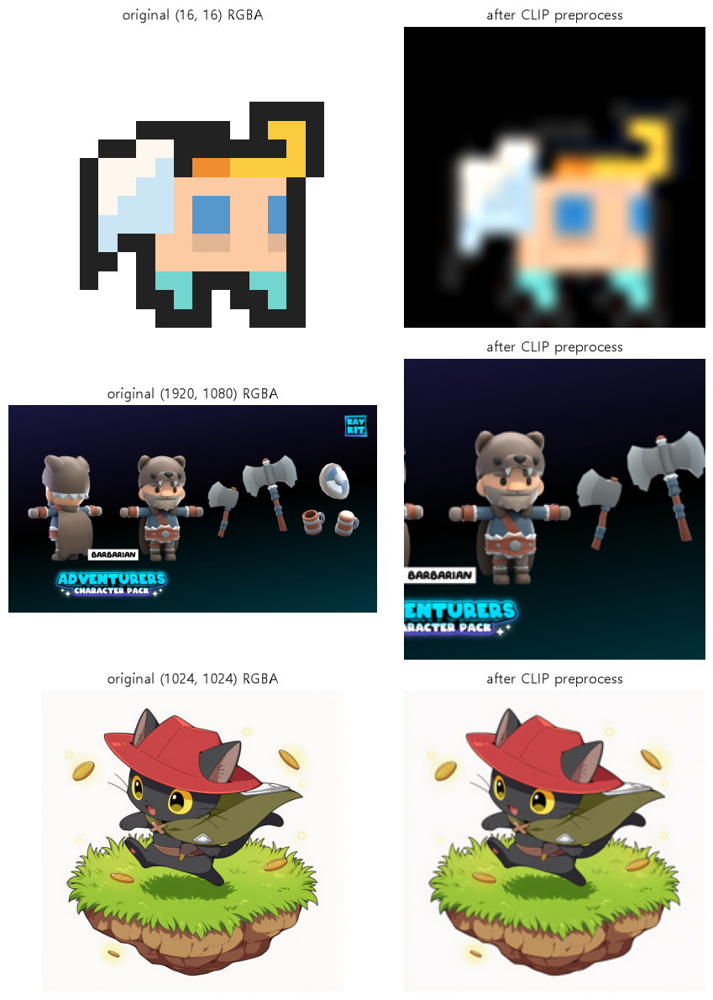

In [11]:
import json
from pathlib import Path
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import transformers
from transformers import CLIPImageProcessor
from huggingface_hub import hf_hub_download

print("transformers", transformers.__version__)

# 실제 IP-Adapter 이미지 인코더 입력 크기 (config.json만 받음, 수 KB)
for sub in ["models/image_encoder", "sdxl_models/image_encoder"]:
    try:
        cfg = json.load(open(hf_hub_download("h94/IP-Adapter", f"{sub}/config.json")))
        print(sub, "image_size =", cfg.get("vision_config", cfg).get("image_size"))
    except Exception as e:
        print(sub, "실패:", e)

proc = CLIPImageProcessor(size=224, crop_size=224)   # diffusers가 만드는 방식과 동일
print("size:", proc.size, "| crop_size:", proc.crop_size,
      "| do_center_crop:", proc.do_center_crop, "| do_convert_rgb:", proc.do_convert_rgb)

paths = [next(Path("../data/raw/pixel_0x72").rglob("*_idle_anim_f0.png")),
         next(Path("../data/raw/kaykit").rglob("Samples/*.png")),
         next(Path("../data/raw/nai").glob("*.png"))]

def to_img(px):
    mean = np.array(proc.image_mean)[:, None, None]
    std = np.array(proc.image_std)[:, None, None]
    return np.clip((px[0] * std + mean).transpose(1, 2, 0), 0, 1)

fig, axes = plt.subplots(len(paths), 2, figsize=(9, 4 * len(paths)))
for r, p in enumerate(paths):
    im = Image.open(p)
    a = np.array(im.convert("RGBA"))
    tr = a[..., 3] == 0
    print(f"\n{p.name} mode={im.mode} size={im.size} transparent_ratio={tr.mean():.3f}")
    if tr.any():
        print("  투명 픽셀의 RGB 고유값(최대 5개):", np.unique(a[tr][:, :3], axis=0)[:5].tolist())
    px = proc(images=im, return_tensors="np")["pixel_values"]
    print("  전처리 후 shape:", px.shape)
    axes[r, 0].imshow(im); axes[r, 0].set_title(f"original {im.size} {im.mode}")
    axes[r, 1].imshow(to_img(px)); axes[r, 1].set_title("after CLIP preprocess")
    for ax in axes[r]: ax.axis("off")
plt.tight_layout(); plt.show()

## 6. 학습 데이터 (10/16 확보분)

1~4번은 처음 받은 원본(NAI 17장, 0x72 프레임 210장, KayKit 미리보기 6장)을 본 것이다. 이 섹션은 10/16에 확보한 학습 데이터 1,840장으로 모델 비교와 LoRA 실험의 입력 조건을 정한다.

| 게임 | 데이터 | 폴더 |
|---|---|---|
| 냥기사의 여행 | NAI 생성 이미지 800장 | `data/raw/nai/lora_gen` |
| 0x72 | 원본 타일·스프라이트를 조합한 장면 520장 | `data/raw/pixel_0x72/scenes` |
| KayKit | 캐릭터 모델 Blender 렌더 520장 | `data/raw/kaykit/renders` |

In [12]:
DATASETS = {
    'nai': sorted((NAI_DIR / 'lora_gen').glob('gen_*.png')),
    'x72': sorted((PIX_DIR / 'scenes').glob('x72_scene_*.png')),
    'kaykit': sorted((KAY_DIR / 'renders').glob('kk_*.png')),
}
nai_info = pd.read_csv(NAI_DIR / 'lora_gen' / 'prompts.csv')
kk_info = pd.read_csv(KAY_DIR / 'renders' / 'renders_index.csv')
x72_info = pd.read_csv(PIX_DIR / 'scenes' / 'scene_log.csv')
for k, v in DATASETS.items():
    print(f'{k:7s} {len(v)}장')

nai     800장
x72     520장
kaykit  520장


### 6-1. 이미지 형식·크기

IP-Adapter 이미지 전처리는 RGB가 아닌 이미지를 `convert("RGB")`로 바꿔 알파를 버리고(transformers 5.19.0 `image_transforms.py` 774줄), 짧은 변을 224로 줄인 뒤 가운데 224×224를 자른다(`models/clip/image_processing_clip.py` 27·29줄, 5번 요약 아래 CLIP 전처리 확인 셀 출력 `do_center_crop: True`, `do_convert_rgb: True`). 그래서 모드(알파 유무)와 가로세로 비율을 확인한다.

,dataset,mode,w,h,n
0,kaykit,RGB,1024,1024,520
1,nai,RGBA,1024,1024,800
2,x72,RGB,1024,1024,520


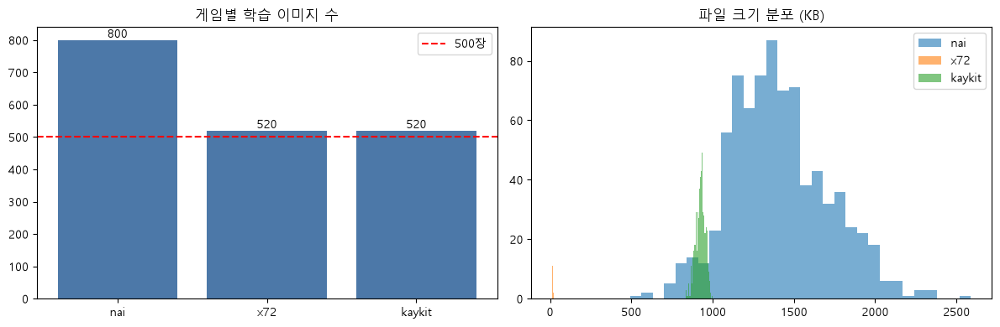

In [13]:
img_rows = []
for name, files in DATASETS.items():
    for f in files:
        with Image.open(f) as im:
            img_rows.append({'dataset': name, 'file': f.name, 'mode': im.mode, 'w': im.width, 'h': im.height,
                             'kb': f.stat().st_size / 1024})
meta = pd.DataFrame(img_rows)
meta.to_csv(FIG_DIR / 'train_image_meta.csv', index=False, encoding='utf-8-sig')
display(meta.groupby(['dataset', 'mode', 'w', 'h']).size().rename('n').reset_index())

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
counts = meta['dataset'].value_counts().reindex(DATASETS)
a1.bar(counts.index, counts.values, color='#4C78A8')
a1.bar_label(a1.containers[0])
a1.axhline(500, color='red', linestyle='--', label='500장')
a1.set_title('게임별 학습 이미지 수')
a1.legend()
for name in DATASETS:
    a2.hist(meta.loc[meta.dataset == name, 'kb'], bins=30, alpha=0.6, label=name)
a2.set_title('파일 크기 분포 (KB)')
a2.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'train_overview.png', dpi=100)
plt.show()

### 6-2. NAI 이미지의 알파 채널

NAI 이미지는 RGBA로 저장되고 일부 픽셀의 알파가 255보다 작다. 실제 투명 영역인지, NAI가 알파 최하위 비트에 넣는 생성 정보(stealth pnginfo, 시작 문자열 `stealth_pngcomp`)인지 확인한다. 생성 정보라면 RGB로 바꿔도 화면 내용은 같다.

,below255_pct,min_alpha
count,800.000,800.0
mean,0.509,254.0
std,0.017,0.0
min,0.481,254.0
25%,0.495,254.0
50%,0.504,254.0
75%,0.527,254.0
max,0.545,254.0


magic
stealth_pngcomp    800
Name: count, dtype: int64

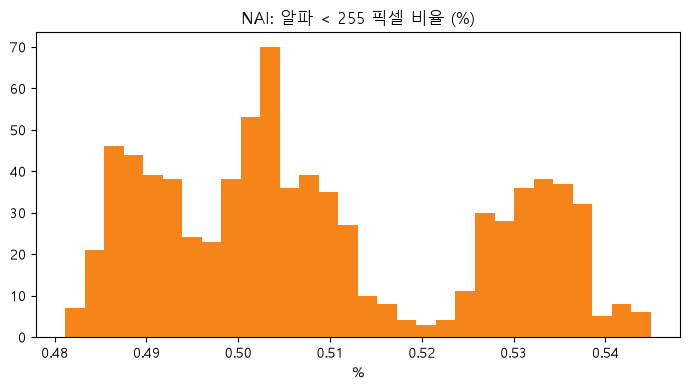

In [14]:
def alpha_stats(path):
    a = np.array(Image.open(path))[..., 3]
    # NAI는 알파 최하위 비트를 열 우선 순서로 기록 → 앞 15바이트가 시작 문자열
    magic = np.packbits((a.T.flatten() & 1)[:8 * 15]).tobytes().decode('latin1')
    return {'file': Path(path).name, 'below255_pct': (a < 255).mean() * 100, 'min_alpha': int(a.min()), 'magic': magic}

nai_alpha = pd.DataFrame([alpha_stats(f) for f in DATASETS['nai']])
display(nai_alpha[['below255_pct', 'min_alpha']].describe().round(3))
display(nai_alpha['magic'].value_counts())

fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(nai_alpha['below255_pct'], bins=30, color='#F58518')
ax.set_title('NAI: 알파 < 255 픽셀 비율 (%)')
ax.set_xlabel('%')
plt.tight_layout()
plt.savefig(FIG_DIR / 'train_nai_alpha.png', dpi=100)
plt.show()

### 6-3. 카테고리·메타데이터 분포

학습/평가 분할을 카테고리 비율대로 나누기 위해 데이터마다 묶음 기준을 확인한다.

- NAI: 프롬프트 카테고리 (`prompts.csv`)
- KayKit: 캐릭터 × 카메라 각도 × 동작 (`renders_index.csv`)
- 0x72: 장면에 들어간 개체 (`scene_log.csv`)

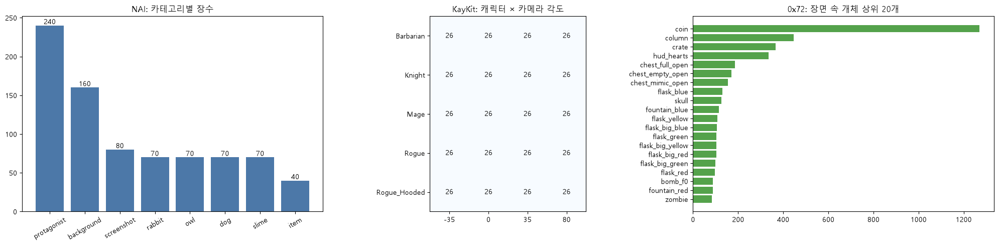

KayKit 캐릭터별 동작 수: {'Barbarian': 26, 'Knight': 26, 'Mage': 26, 'Rogue': 26, 'Rogue_Hooded': 26}
KayKit 소품 없는 이미지: 192 | 배경색별 장수: {'0.02,0.02,0.06': 122, '0.60,0.75,0.60': 118, '0.05,0.08,0.15': 103, '0.75,0.82,0.90': 93, '0.90,0.85,0.75': 84}
0x72 개체 종류: 76 | 장면당 개체 수: {'count': 520.0, 'mean': 12.6, 'std': 3.0, 'min': 5.0, '25%': 10.0, '50%': 13.0, '75%': 15.0, 'max': 21.0}


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
c = nai_info['category'].value_counts()
axes[0].bar(c.index, c.values, color='#4C78A8')
axes[0].bar_label(axes[0].containers[0])
axes[0].set_title('NAI: 카테고리별 장수')
axes[0].tick_params(axis='x', rotation=30)

ct = pd.crosstab(kk_info['character'], kk_info['yaw'])
axes[1].imshow(ct.values, cmap='Blues')
axes[1].set_xticks(range(len(ct.columns)), ct.columns)
axes[1].set_yticks(range(len(ct.index)), ct.index)
for i in range(ct.shape[0]):
    for j in range(ct.shape[1]):
        axes[1].text(j, i, ct.values[i, j], ha='center', va='center')
axes[1].set_title('KayKit: 캐릭터 × 카메라 각도')

ents = x72_info['entities'].str.split('|').explode().value_counts().head(20)
axes[2].barh(ents.index[::-1], ents.values[::-1], color='#54A24B')
axes[2].set_title('0x72: 장면 속 개체 상위 20개')
plt.tight_layout()
plt.savefig(FIG_DIR / 'train_distributions.png', dpi=100)
plt.show()
print('KayKit 캐릭터별 동작 수:', kk_info.groupby('character')['action'].nunique().to_dict())
print('KayKit 소품 없는 이미지:', kk_info['props'].isna().sum(), '| 배경색별 장수:', kk_info['bg'].value_counts().to_dict())
print('0x72 개체 종류:', x72_info['entities'].str.split('|').explode().nunique(),
      '| 장면당 개체 수:', x72_info['n_entities'].describe().round(1).to_dict())

### 6-4. 1-3 밝기·채도 기준 검증

1-3은 "같은 그림체라면 밝기·채도 분포가 모여 있어야 하고, 흩어진 이미지는 제외 후보"로 정했지만 근거가 없다. 이 기준이 그림체를 거르는지 확인한다.

- 1-3과 같은 계산(256×256 축소 후 HSV 평균 채도·밝기)을 학습 데이터 1,840장에 적용한다.
- 제외 후보 = NAI 800장 평균±2표준편차 밖. NAI 800장은 같은 모델·같은 설정으로 생성했으므로, 기준이 그림체를 거른다면 제외 후보가 거의 없어야 한다.
- 제외 후보와 나머지의 프롬프트 키워드(시간대·장소) 비율을 비교한다. 차이가 크면 기준이 그림체가 아니라 장면 내용을 거르는 것이다.
- 그림체가 다른 KayKit·0x72가 NAI 범위 안에 얼마나 들어오는지 본다. 많이 들어오면 다른 그림체를 걸러내지 못한다.

saturation        brightness       
                  mean    std       mean    std
group                                          
background       0.476  0.105      0.758  0.095
dog              0.305  0.073      0.786  0.065
item             0.197  0.038      0.799  0.033
kaykit           0.267  0.153      0.523  0.203
owl              0.299  0.075      0.785  0.059
protagonist      0.388  0.126      0.666  0.079
rabbit           0.301  0.069      0.786  0.069
screenshot       0.406  0.086      0.742  0.104
slime            0.470  0.102      0.807  0.096
x72              0.114  0.015      0.170  0.024

NAI 제외 후보: 52 / 800


,sum,count,pct
group,,,
background,15,160,9.4
dog,0,70,0.0
item,2,40,5.0
owl,0,70,0.0
protagonist,24,240,10.0
rabbit,0,70,0.0
screenshot,4,80,5.0
slime,7,70,10.0


다른 게임 중 NAI 범위 안에 들어오는 비율(%): {'kaykit': 26.7, 'x72': 0.0}


,night,evening,morning,daytime,cave,dungeon,torch
제외 후보,69.2,1.9,5.8,0.0,17.3,7.7,3.8
나머지,19.3,2.5,13.0,13.4,3.6,7.0,0.8


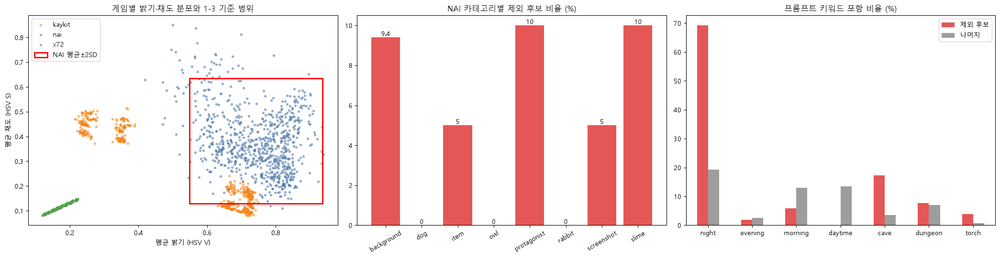

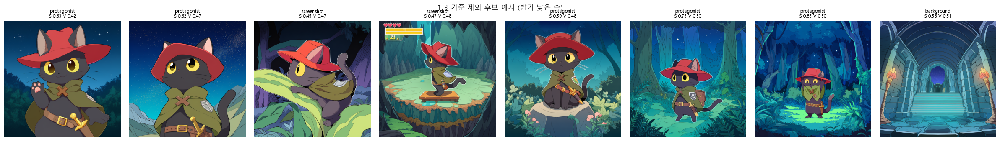

In [16]:
def hsv_stats(path):
    hsv = np.asarray(Image.open(path).convert('RGB').resize((256, 256)).convert('HSV'), dtype=np.float32) / 255
    return hsv[..., 1].mean(), hsv[..., 2].mean()

nai_cat = nai_info.set_index('file')['category']
nai_prompt = nai_info.set_index('file')['prompt']
cs_rows = []
for k, files in DATASETS.items():
    for f in files:
        s, v = hsv_stats(f)
        cs_rows.append({'dataset': k, 'file': f.name, 'group': nai_cat[f.name] if k == 'nai' else k,
                        'saturation': s, 'brightness': v})
cs = pd.DataFrame(cs_rows)
ref = cs[cs.dataset == 'nai']
mu, sd = ref[['saturation', 'brightness']].mean(), ref[['saturation', 'brightness']].std()
z = (cs[['saturation', 'brightness']] - mu) / sd
cs['excluded'] = z.abs().max(axis=1) > 2
cs.to_csv(FIG_DIR / 'train_color_stats.csv', index=False, encoding='utf-8-sig')

display(cs.groupby('group')[['saturation', 'brightness']].agg(['mean', 'std']).round(3))
nai_cs = cs[cs.dataset == 'nai'].copy()
by_cat = nai_cs.groupby('group')['excluded'].agg(['sum', 'count']).assign(pct=lambda d: (d['sum'] / d['count'] * 100).round(1))
print('NAI 제외 후보:', int(nai_cs.excluded.sum()), '/', len(nai_cs))
display(by_cat)
inside = cs[cs.dataset != 'nai'].groupby('dataset')['excluded'].apply(lambda s: round((~s).mean() * 100, 1))
print('다른 게임 중 NAI 범위 안에 들어오는 비율(%):', inside.to_dict())

KEYWORDS = ['night', 'evening', 'morning', 'daytime', 'cave', 'dungeon', 'torch']
for kw in KEYWORDS:
    nai_cs[kw] = nai_cs.file.map(lambda f: kw in nai_prompt[f])
kw_pct = pd.DataFrame({'제외 후보': nai_cs[nai_cs.excluded][KEYWORDS].mean() * 100,
                       '나머지': nai_cs[~nai_cs.excluded][KEYWORDS].mean() * 100}).round(1)
display(kw_pct.T)

fig, axes = plt.subplots(1, 3, figsize=(21, 5.5))
colors = {'nai': '#4C78A8', 'x72': '#54A24B', 'kaykit': '#F58518'}
for k, g in cs.groupby('dataset'):
    axes[0].scatter(g.brightness, g.saturation, s=8, alpha=0.5, color=colors[k], label=k)
lo, hi = mu - 2 * sd, mu + 2 * sd
axes[0].add_patch(plt.Rectangle((lo.brightness, lo.saturation), hi.brightness - lo.brightness,
                                hi.saturation - lo.saturation, fill=False, color='red', lw=2, label='NAI 평균±2SD'))
axes[0].set_xlabel('평균 밝기 (HSV V)')
axes[0].set_ylabel('평균 채도 (HSV S)')
axes[0].set_title('게임별 밝기·채도 분포와 1-3 기준 범위')
axes[0].legend()
axes[1].bar(by_cat.index, by_cat.pct, color='#E45756')
axes[1].bar_label(axes[1].containers[0])
axes[1].set_title('NAI 카테고리별 제외 후보 비율 (%)')
axes[1].tick_params(axis='x', rotation=30)
kw_pct.plot.bar(ax=axes[2], color=['#E45756', '#9D9D9D'])
axes[2].set_title('프롬프트 키워드 포함 비율 (%)')
axes[2].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig(FIG_DIR / 'train_color_criterion_check.png', dpi=100)
plt.show()

ex = nai_cs[nai_cs.excluded].sort_values('brightness').head(8)
fig, axes = plt.subplots(1, len(ex), figsize=(3 * len(ex), 3.4))
for ax, r in zip(axes, ex.itertuples()):
    ax.imshow(Image.open(NAI_DIR / 'lora_gen' / r.file).convert('RGB'))
    ax.set_title(f'{r.group}\nS {r.saturation:.2f} V {r.brightness:.2f}', fontsize=8)
    ax.axis('off')
plt.suptitle('1-3 기준 제외 후보 예시 (밝기 낮은 순)')
plt.tight_layout()
plt.savefig(FIG_DIR / 'train_color_excluded_examples.png', dpi=80)
plt.show()

### 6-5. 이미지 간 유사도 (누설 확인)

KayKit은 같은 캐릭터·같은 동작을 카메라 각도 4개로 렌더했다. 각도만 다른 이미지가 학습과 평가에 나뉘어 들어가면 평가 점수가 부풀 수 있다. CLIP 이미지 임베딩의 코사인 유사도로 데이터마다 가장 가까운 이미지와의 유사도를 보고, KayKit은 같은 묶음(캐릭터+동작) 안과 밖의 유사도를 비교한다.

- 여기서 쓰는 CLIP(`openai/clip-vit-base-patch32`)은 EDA용 유사도 계산에만 쓴다. LoRA 실험의 그림체 유사도 지표는 따로 정한다.

In [17]:
import torch
from transformers import CLIPModel, CLIPProcessor

CLIP_ID = 'openai/clip-vit-base-patch32'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
clip = CLIPModel.from_pretrained(CLIP_ID).to(device).eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID)


@torch.no_grad()
def embed(files, bs=32):
    out = []
    for i in range(0, len(files), bs):
        # NAI 알파는 6-2에서 생성 정보로 확인 → RGB 변환해도 화면 내용은 같음
        ims = [Image.open(f).convert('RGB') for f in files[i:i + bs]]
        x = clip_proc(images=ims, return_tensors='pt').to(device)
        # transformers 5.x: get_image_features는 출력 객체를 반환, 투영된 임베딩은 pooler_output (modeling_clip.py 742줄)
        e = clip.get_image_features(**x).pooler_output
        out.append(torch.nn.functional.normalize(e, dim=-1).float().cpu())
    return torch.cat(out).numpy()


EMB = {k: embed(v) for k, v in DATASETS.items()}
np.savez(FIG_DIR / 'train_clip_embeddings.npz', **EMB)
print({k: v.shape for k, v in EMB.items()})

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 22288.09it/s]


{'nai': (800, 512), 'x72': (520, 512), 'kaykit': (520, 512)}


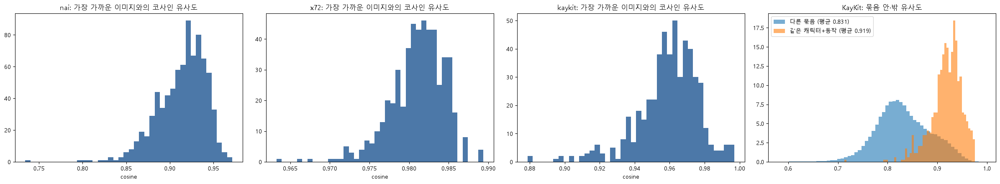

,count,mean,std,min,25%,50%,75%,max
dataset,,,,,,,,
kaykit,520.0,0.959,0.018,0.879,0.951,0.961,0.971,0.997
nai,800.0,0.914,0.028,0.734,0.898,0.919,0.934,0.972
x72,520.0,0.981,0.003,0.963,0.979,0.981,0.983,0.989


In [18]:
fig, axes = plt.subplots(1, 4, figsize=(24, 4.5))
nn_rows = []
for ax, (k, E) in zip(axes, EMB.items()):
    S = E @ E.T
    np.fill_diagonal(S, -1)
    for i, (s, j) in enumerate(zip(S.max(1), S.argmax(1))):
        nn_rows.append({'dataset': k, 'file': DATASETS[k][i].name, 'nearest': DATASETS[k][j].name, 'cos': float(s)})
    ax.hist(S.max(1), bins=40, color='#4C78A8')
    ax.set_title(f'{k}: 가장 가까운 이미지와의 코사인 유사도')
    ax.set_xlabel('cosine')
nn_df = pd.DataFrame(nn_rows)
nn_df.to_csv(FIG_DIR / 'train_nearest_neighbors.csv', index=False, encoding='utf-8-sig')

kk_names = [f.name for f in DATASETS['kaykit']]
grp = kk_info.set_index('short_name').loc[kk_names, ['character', 'action']].agg('|'.join, axis=1).to_numpy(dtype=str)
S = EMB['kaykit'] @ EMB['kaykit'].T
same = grp[:, None] == grp[None, :]
off = ~np.eye(len(grp), dtype=bool)
within, across = S[same & off], S[~same]
axes[3].hist(across, bins=60, alpha=0.6, density=True, label=f'다른 묶음 (평균 {across.mean():.3f})')
axes[3].hist(within, bins=60, alpha=0.6, density=True, label=f'같은 캐릭터+동작 (평균 {within.mean():.3f})')
axes[3].set_title('KayKit: 묶음 안·밖 유사도')
axes[3].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / 'train_similarity.png', dpi=100)
plt.show()
display(nn_df.groupby('dataset')['cos'].describe().round(3))

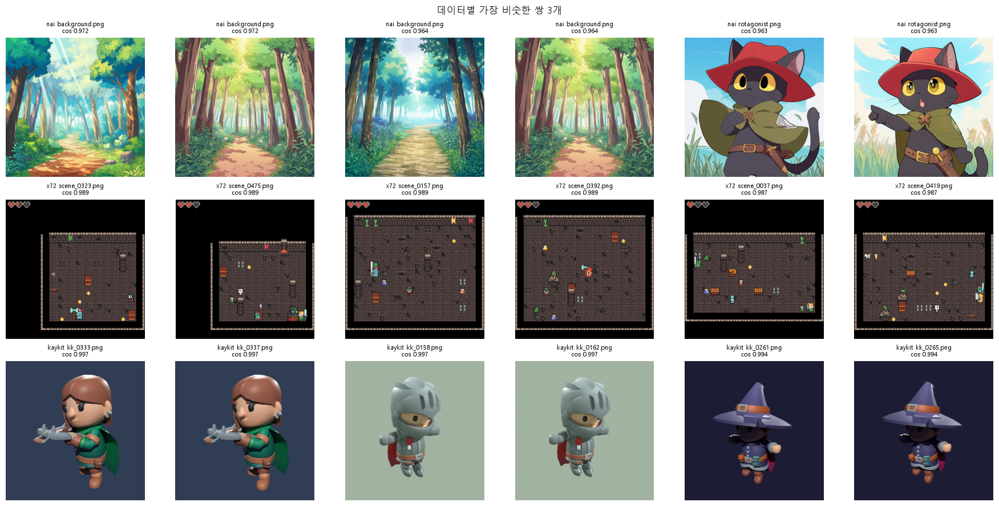

In [19]:
fig, axes = plt.subplots(3, 6, figsize=(18, 9))
for r, k in enumerate(DATASETS):
    top = nn_df[nn_df.dataset == k].sort_values('cos', ascending=False)
    top = top[top['file'] < top['nearest']].head(3)
    base = DATASETS[k][0].parent
    for c, (_, row) in enumerate(top.iterrows()):
        for d, f in enumerate([row['file'], row['nearest']]):
            ax = axes[r, c * 2 + d]
            ax.imshow(Image.open(base / f).convert('RGB'))
            ax.set_title(f'{k} {f[-14:]}\ncos {row.cos:.3f}', fontsize=8)
            ax.axis('off')
plt.suptitle('데이터별 가장 비슷한 쌍 3개')
plt.tight_layout()
plt.savefig(FIG_DIR / 'train_most_similar_pairs.png', dpi=80)
plt.show()

### 6-6. IP-Adapter 참조 이미지 후보

묶음(NAI는 카테고리, KayKit은 캐릭터, 0x72는 전체)마다 CLIP 임베딩 평균에 가장 가까운 이미지 3장을 대표 후보로 뽑는다. 최종 참조 이미지는 이 후보를 보고 정한다.

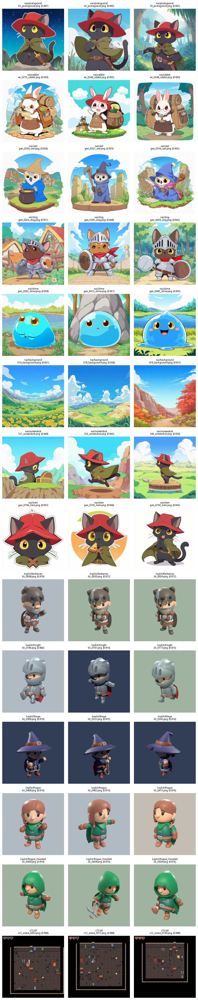

In [20]:
groups = [('nai', nai_cat[f.name], i) for i, f in enumerate(DATASETS['nai'])]
groups += [('kaykit', kk_info.set_index('short_name').loc[n, 'character'], i) for i, n in enumerate(kk_names)]
groups += [('x72', 'all', i) for i in range(len(DATASETS['x72']))]
gdf = pd.DataFrame(groups, columns=['dataset', 'group', 'i'])

picks = []
for (k, g), sub in gdf.groupby(['dataset', 'group'], sort=False):
    E = EMB[k][sub['i'].values]
    center = E.mean(0) / np.linalg.norm(E.mean(0))
    score = E @ center
    for j in np.argsort(-score)[:3]:
        picks.append({'dataset': k, 'group': g, 'file': DATASETS[k][sub['i'].values[j]].name,
                      'cos_to_center': float(score[j])})
picks = pd.DataFrame(picks)
picks.to_csv(FIG_DIR / 'train_reference_candidates.csv', index=False, encoding='utf-8-sig')

keys = list(picks.groupby(['dataset', 'group'], sort=False).groups)
fig, axes = plt.subplots(len(keys), 3, figsize=(9, 3.2 * len(keys)), squeeze=False)
for r, (k, g) in enumerate(keys):
    sub = picks[(picks.dataset == k) & (picks.group == g)]
    for c, (_, row) in enumerate(sub.iterrows()):
        ax = axes[r, c]
        ax.imshow(Image.open(DATASETS[k][0].parent / row['file']).convert('RGB'))
        ax.set_title(f"{k}/{g}\n{row['file'][-18:]} ({row.cos_to_center:.3f})", fontsize=8)
        ax.axis('off')
plt.tight_layout()
plt.savefig(FIG_DIR / 'train_reference_candidates.png', dpi=70)
plt.show()

### 6-7. 이 섹션 결과로 정할 것

| 항목 | 확인할 출력 |
|---|---|
| 투명 배경 처리 필요 여부 | 6-1 표(모드), 6-2 시작 문자열과 알파 비율 |
| IP-Adapter 크롭 처리 필요 여부 | 6-1 표(가로세로 크기) |
| 1-3 밝기·채도 기준 유지 여부 | 6-4 제외 후보 비율, 키워드 비교, 다른 게임 포함 비율 |
| 학습/평가 분할 기준 | 6-3 분포, 6-5 KayKit 묶음 안·밖 유사도 |
| 거의 같은 이미지 제거 여부 | 6-5 가장 가까운 이미지 유사도 분포와 가장 비슷한 쌍 |
| IP-Adapter 참조 이미지 | 6-6 후보 |